<a href="https://colab.research.google.com/github/ohJeez/Restaurant-Ai/blob/main/Demand_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
sales = pd.read_csv(
    "/content/demand_model_dataset.csv"
)

calendar = pd.read_csv(
    "/content/calendar.csv"
)

print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)

Sales shape: (17544, 12)
Calendar shape: (731, 10)


In [ ]:
sales.head()
sales.info()
sales.describe()
print("Number of items:",
      sales["item_id"].nunique())

print("Number of dates:",
      sales["date"].nunique())

print("Date range:",
      sales["date"].min(),
      "to",
      sales["date"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           17544 non-null  object 
 1   item_id        17544 non-null  object 
 2   item_name      17544 non-null  object 
 3   category       17544 non-null  object 
 4   quantity_sold  17544 non-null  int64  
 5   revenue        17544 non-null  int64  
 6   day_of_week    17544 non-null  int64  
 7   is_weekend     17544 non-null  int64  
 8   month          17544 non-null  int64  
 9   lag_1          17520 non-null  float64
 10  lag_7          17376 non-null  float64
 11  rolling_7      17376 non-null  float64
dtypes: float64(3), int64(5), object(4)
memory usage: 1.6+ MB
Number of items: 24
Number of dates: 731
Date range: 2024-01-01 to 2025-12-31


In [ ]:
sales["date"] = pd.to_datetime(
    sales["date"]
)

calendar["date"] = pd.to_datetime(
    calendar["date"]
)


In [ ]:
sales = sales.sort_values(
    ["item_id", "date"]
)

In [ ]:
df = sales.merge(
    calendar[
        [
            "date",
            "is_holiday",
            "promotion_flag",
            "weather",
            "temperature_c"
        ]
    ],
    on="date",
    how="left"
)

print(df.shape)

df.head()

(17544, 16)


,date,item_id,item_name,category,quantity_sold,revenue,day_of_week,is_weekend,month,lag_1,lag_7,rolling_7,is_holiday,promotion_flag,weather,temperature_c
0,2024-01-01,F001,Chicken Biryani,Main Course,131,23580,0,0,1,NaN,NaN,NaN,1,0,Rainy,27.3
1,2024-01-02,F001,Chicken Biryani,Main Course,80,14400,1,0,1,131.0,NaN,NaN,0,0,Cloudy,24.9
2,2024-01-03,F001,Chicken Biryani,Main Course,106,19080,2,0,1,80.0,NaN,NaN,0,0,Rainy,27.8
3,2024-01-04,F001,Chicken Biryani,Main Course,75,13500,3,0,1,106.0,NaN,NaN,0,0,Rainy,31.1
4,2024-01-05,F001,Chicken Biryani,Main Course,89,16020,4,0,1,75.0,NaN,NaN,0,0,Sunny,25.1


In [ ]:
df["day"] = df["date"].dt.day

df["day_of_week"] = (
    df["date"].dt.dayofweek
)

df["week_of_year"] = (
    df["date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

df["month"] = (
    df["date"].dt.month
)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

In [ ]:
df["lag_1"] = (
    df.groupby("item_id")["quantity_sold"]
    .shift(1)
)

df["lag_7"] = (
    df.groupby("item_id")["quantity_sold"]
    .shift(7)
)

df["lag_14"] = (
    df.groupby("item_id")["quantity_sold"]
    .shift(14)
)

df["lag_28"] = (
    df.groupby("item_id")["quantity_sold"]
    .shift(28)
)

In [ ]:
df["rolling_7"] = (
    df.groupby("item_id")["quantity_sold"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(7)
        .mean()
    )
)

df["rolling_14"] = (
    df.groupby("item_id")["quantity_sold"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(14)
        .mean()
    )
)

df["rolling_30"] = (
    df.groupby("item_id")["quantity_sold"]
    .transform(
        lambda x:
        x.shift(1)
        .rolling(30)
        .mean()
    )
)

In [ ]:
df = df.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "rolling_7",
        "rolling_14",
        "rolling_30"
    ]
)

In [ ]:
print(df.shape)

(16824, 22)


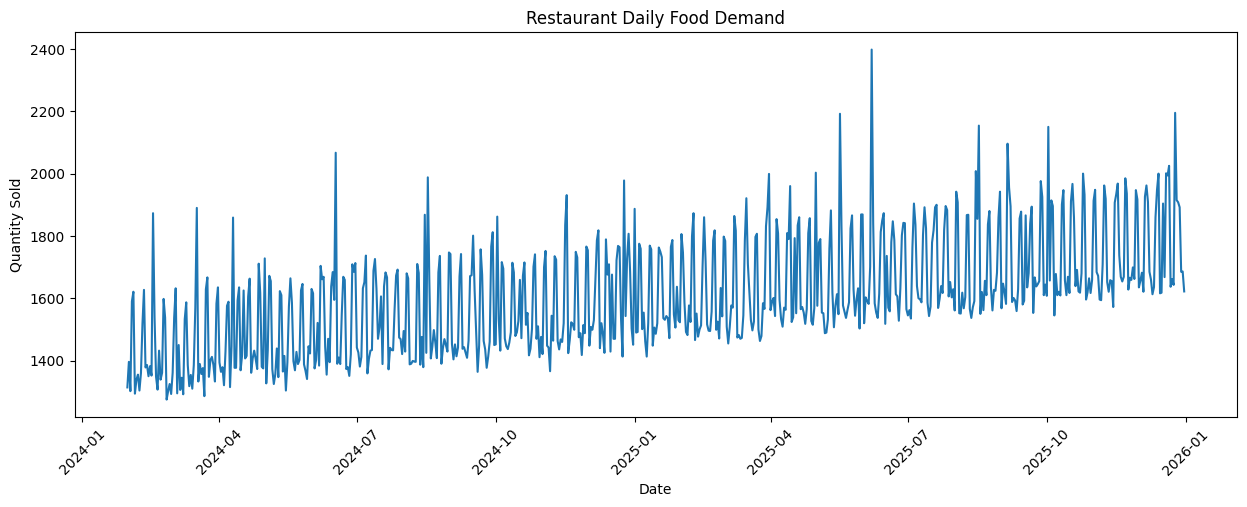

In [ ]:
daily_demand = (
    df.groupby("date")["quantity_sold"]
    .sum()
)

plt.figure(figsize=(15, 5))

plt.plot(
    daily_demand.index,
    daily_demand.values
)

plt.title(
    "Restaurant Daily Food Demand"
)

plt.xlabel("Date")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)

plt.show()

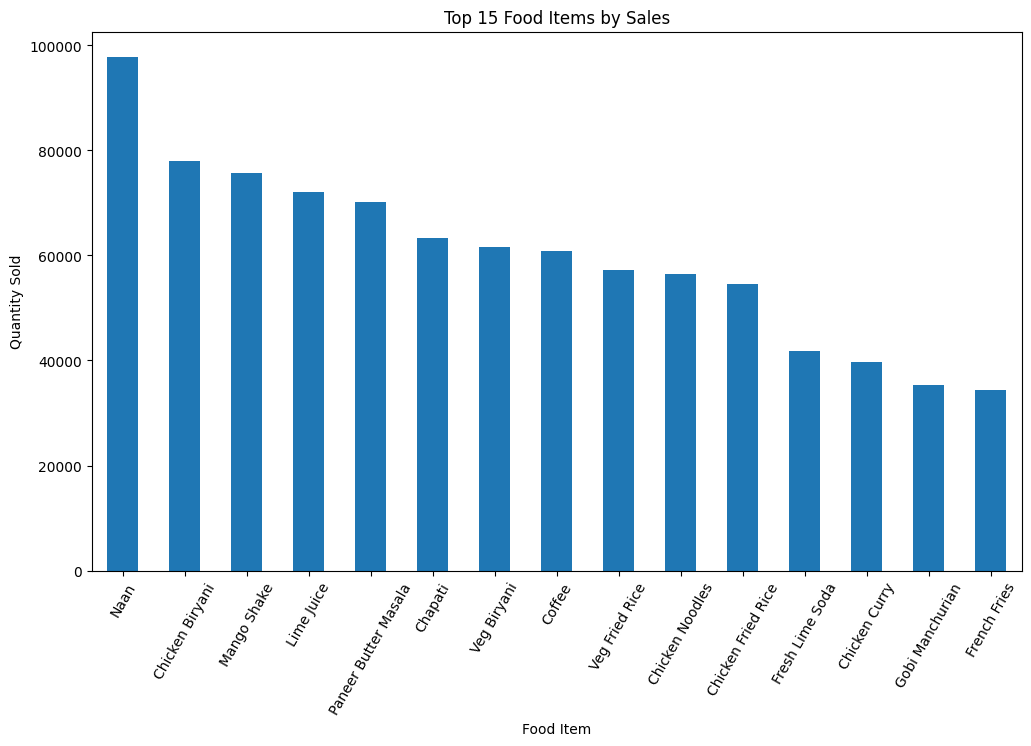

In [ ]:
item_sales = (
    df.groupby("item_name")["quantity_sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

item_sales.head(15).plot(
    kind="bar"
)

plt.title(
    "Top 15 Food Items by Sales"
)

plt.xlabel("Food Item")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=60)

plt.show()

In [ ]:
numeric_features = [
    "day",
    "day_of_week",
    "week_of_year",
    "month",
    "is_weekend",
    "is_holiday",
    "promotion_flag",
    "temperature_c",

    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",

    "rolling_7",
    "rolling_14",
    "rolling_30"
]

In [ ]:
categorical_features = [
    "item_id",
    "category",
    "weather"
]

In [ ]:
features = (
    numeric_features +
    categorical_features
)

target = "quantity_sold"

In [ ]:
split_date = pd.Timestamp(
    "2025-07-01"
)

train_df = df[
    df["date"] < split_date
].copy()

test_df = df[
    df["date"] >= split_date
].copy()

print(
    "Training:",
    train_df.shape
)

print(
    "Testing:",
    test_df.shape
)

Training: (12408, 22)
Testing: (4416, 22)


In [ ]:
X_train = train_df[features]

y_train = train_df[target]

X_test = test_df[features]

y_test = test_df[target]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",

            OneHotEncoder(
                handle_unknown="ignore"
            ),

            categorical_features
        ),

        (
            "numeric",

            "passthrough",

            numeric_features
        )
    ]
)

In [ ]:
linear_model = Pipeline(
    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",
            LinearRegression()
        )
    ]
)

linear_model.fit(
    X_train,
    y_train
)

linear_pred = linear_model.predict(
    X_test
)

In [ ]:
rf_model = Pipeline(
    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",

            RandomForestRegressor(
                n_estimators=300,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

In [ ]:
xgb_model = Pipeline(
    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",

            XGBRegressor(
                n_estimators=500,
                max_depth=7,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42
            )
        )
    ]
)

xgb_model.fit(
    X_train,
    y_train
)

xgb_pred = xgb_model.predict(
    X_test
)

In [ ]:
def evaluate_model(
    name,
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    print(
        f"\n{name}"
    )

    print(
        "MAE :",
        round(mae, 2)
    )

    print(
        "RMSE:",
        round(rmse, 2)
    )

    print(
        "R²  :",
        round(r2, 4)
    )

    return mae, rmse, r2

In [ ]:
linear_results = evaluate_model(
    "Linear Regression",
    y_test,
    linear_pred
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_pred
)

xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_pred
)


Linear Regression
MAE : 7.62
RMSE: 9.95
R²  : 0.921

Random Forest
MAE : 7.5
RMSE: 9.77
R²  : 0.9239

XGBoost
MAE : 7.3
RMSE: 9.56
R²  : 0.9271


In [ ]:
results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],

    "MAE": [
        linear_results[0],
        rf_results[0],
        xgb_results[0]
    ],

    "RMSE": [
        linear_results[1],
        rf_results[1],
        xgb_results[1]
    ],

    "R2": [
        linear_results[2],
        rf_results[2],
        xgb_results[2]
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,7.619416,9.951695,0.920985
1,Random Forest,7.502473,9.768210,0.923872
2,XGBoost,7.301468,9.557596,0.927119


In [ ]:
joblib.dump(
    xgb_model,
    "/content/demand_model_v2.joblib"
)

print(
    "Demand Model V2 saved!"
)

Demand Model V2 saved!


In [ ]:
loaded_model = joblib.load(
    "/content/demand_model_v2.joblib"
)

test_prediction = loaded_model.predict(
    X_test.head(5)
)

print(test_prediction)

[104.76309 111.87324 105.39483 113.51771 130.41402]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "model__n_estimators": [200, 300, 500, 700, 1000],
    "model__max_depth": [3, 5, 7, 9, 12],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [ ]:
tuning = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [ ]:
tuning.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('categorical',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['item_id',
                                                                                'category',
                                                                                'weather']),
                                                                              ('numeric',
                                                                               'passthrough',
                                                                               ['day',
                                                                                'day_of_week',
                                                                                'week_of_year',
                                                                                'month',
                                                                                'is_weekend',
                                                                                'is_holiday',
                                                                                'promotion_flag',
                                                                                'temperature_c',
                                                                                'lag_1',
                                                                                'lag_7',
                                                                                'lag_14',
                                                                                'lag_28',
                                                                                'r...
                                                           n_jobs=None,
                                                           num_parallel_tree=None, ...))]),
                   n_iter=20, n_jobs=-1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.8,
                                                                    0.9, 1.0],
                                        'model__learning_rate': [0.01, 0.03,
                                                                 0.05, 0.08,
                                                                 0.1],
                                        'model__max_depth': [3, 5, 7, 9, 12],
                                        'model__n_estimators': [200, 300, 500,
                                                                700, 1000],
                                        'model__subsample': [0.7, 0.8, 0.9,
                                                             1.0]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=2)

In [ ]:
# Get the best tuned model
best_model = tuning.best_estimator_

print("Best model loaded successfully.")
print(best_model)

Best model loaded successfully.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['item_id', 'category',
                                                   'weather']),
                                                 ('numeric', 'passthrough',
                                                  ['day', 'day_of_week',
                                                   'week_of_year', 'month',
                                                   'is_weekend', 'is_holiday',
                                                   'promotion_flag',
                                                   'temperature_c', 'lag_1',
                                                   'lag_7', 'lag_14', 'lag_28',
                                                   'rolling_7', 'rolling_14',
                                  

In [ ]:
# Get predictions from tuned model
tuned_pred = best_model.predict(X_test)

# Calculate metrics
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("TUNED XGBOOST RESULTS")
print("========================")
print("MAE :", round(tuned_mae, 4))
print("RMSE:", round(tuned_rmse, 4))
print("R²  :", round(tuned_r2, 4))

TUNED XGBOOST RESULTS
MAE : 7.2503
RMSE: 9.447
R²  : 0.9288


In [ ]:
best_model = tuning.best_estimator_

In [ ]:
import joblib

joblib.dump(best_model, "demand_model_final.joblib")

print("Final demand model saved successfully.")

Final demand model saved successfully.


In [ ]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)

print("Predicted demand:", prediction[0])
print("Actual demand:", y_test.iloc[0])

Predicted demand: 107.18207
Actual demand: 98


In [ ]:
print("Best parameters:")
print(tuning.best_params_)

Best parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}


In [ ]:
from google.colab import files

files.download(
    "/content/demand_model_v2.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Extract the trained XGBoost model
xgb_final = best_model.named_steps["model"]

# Get feature names after preprocessing
preprocessor_final = best_model.named_steps["preprocessor"]

feature_names = preprocessor_final.get_feature_names_out()

# Feature importance
importance = xgb_final.feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
}).sort_values("importance", ascending=False)

print(feature_importance.head(20))

                              feature  importance
48                numeric__rolling_30    0.422927
8           categorical__item_id_F009    0.228168
47                numeric__rolling_14    0.111929
46                 numeric__rolling_7    0.048932
44                    numeric__lag_14    0.029787
38                numeric__is_weekend    0.018545
45                    numeric__lag_28    0.016294
35               numeric__day_of_week    0.015758
43                     numeric__lag_7    0.015398
25        categorical__category_Bread    0.009135
39                numeric__is_holiday    0.008979
40            numeric__promotion_flag    0.006866
24     categorical__category_Beverage    0.006734
12          categorical__item_id_F013    0.005482
28  categorical__category_Main Course    0.004614
31    categorical__weather_Heavy Rain    0.004545
32         categorical__weather_Rainy    0.004243
20          categorical__item_id_F021    0.003595
30        categorical__weather_Cloudy    0.002771


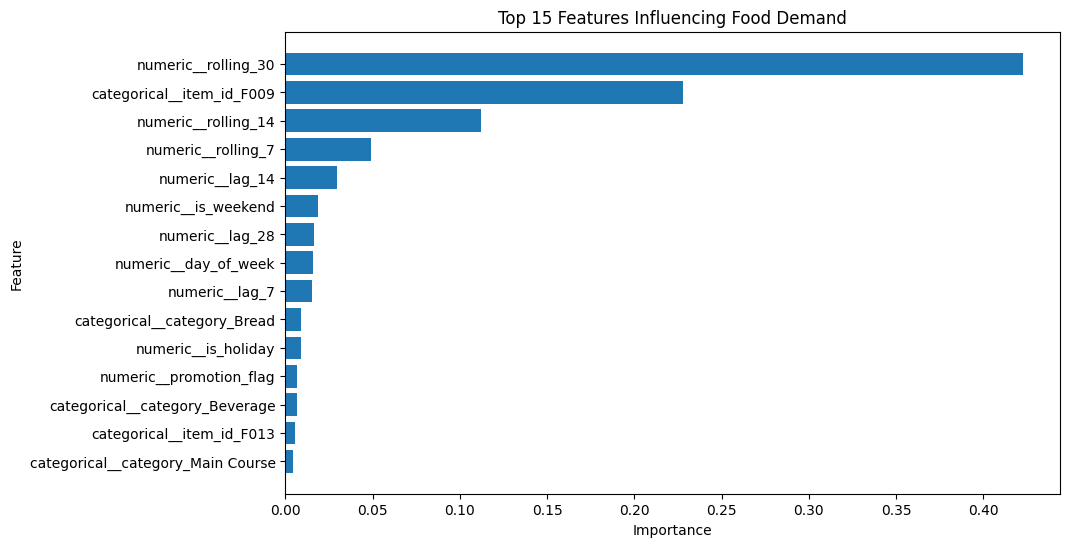

In [ ]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Food Demand")
plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": tuned_pred
})

print(results.head(20))

    Actual   Predicted
0       98  107.182068
1      116  108.305458
2      111  106.063637
3      113  119.990784
4      124  130.312271
5      113  128.119522
6      132  108.374130
7      104  106.067612
8      118  103.300980
9      105  106.299080
10     127  118.993980
11     129  129.116638
12     117  127.846817
13      95  107.790169
14     117  102.337296
15     138  107.416344
16     111  119.174606
17     112  123.373001
18     135  129.332214
19     131  127.979050


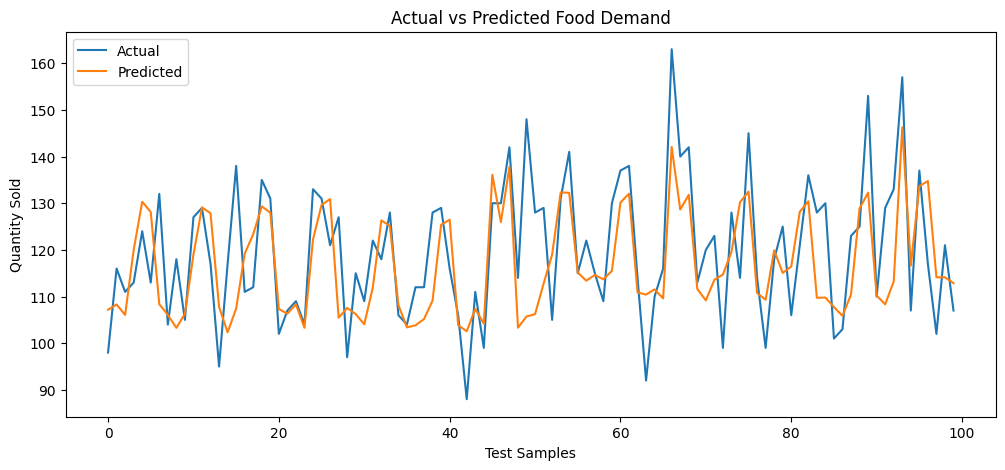

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(results["Actual"].values[:100], label="Actual")
plt.plot(results["Predicted"].values[:100], label="Predicted")

plt.xlabel("Test Samples")
plt.ylabel("Quantity Sold")
plt.title("Actual vs Predicted Food Demand")
plt.legend()
plt.show()

In [ ]:
def predict_demand(input_data):
    prediction = best_model.predict(input_data)
    return max(0, round(prediction[0], 2))

In [ ]:
sample_input = X_test.iloc[[0]]

predicted_demand = predict_demand(sample_input)

print("Predicted Demand:", predicted_demand)
print("Actual Demand:", y_test.iloc[0])

Predicted Demand: 107.18
Actual Demand: 98


In [ ]:
joblib.dump(features, "demand_features.pkl")

print("Feature list saved.")

Feature list saved.


In [ ]:
from google.colab import files

files.download(
    "/content/demand_features.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# MODEL 2: Food Preparation Recommendation

In [ ]:
import pandas as pd
import numpy as np

sales = pd.read_csv("/content/sales.csv")
wastage = pd.read_csv("/content/wastage.csv")
menu = pd.read_csv("/content/menu_items.csv")

sales["date"] = pd.to_datetime(sales["date"])
wastage["date"] = pd.to_datetime(wastage["date"])

print("Sales:", sales.shape)
print("Wastage:", wastage.shape)
print("Menu:", menu.shape)

Sales: (52632, 10)
Wastage: (17544, 7)
Menu: (24, 7)


In [ ]:
waste_summary = (
    wastage
    .groupby("item_id")
    .agg(
        total_prepared=("prepared_quantity", "sum"),
        total_sold=("sold_quantity", "sum"),
        total_wasted=("wasted_quantity", "sum")
    )
    .reset_index()
)

waste_summary["waste_rate"] = (
    waste_summary["total_wasted"] /
    waste_summary["total_prepared"]
)

waste_summary.head()

,item_id,total_prepared,total_sold,total_wasted,waste_rate
0,F001,85340,80939,4464,0.052308
1,F002,29793,28044,1749,0.058705
2,F003,67543,63829,3752,0.055550
3,F004,60033,56621,3440,0.057302
4,F005,62574,59364,3253,0.051986


In [ ]:
prep_data = waste_summary.merge(
    menu[
        [
            "item_id",
            "item_name",
            "category",
            "perishability",
            "minimum_batch"
        ]
    ],
    on="item_id",
    how="left"
)

prep_data.head()

,item_id,total_prepared,total_sold,total_wasted,waste_rate,item_name,category,perishability,minimum_batch
0,F001,85340,80939,4464,0.052308,Chicken Biryani,Main Course,High,20
1,F002,29793,28044,1749,0.058705,Beef Biryani,Main Course,High,20
2,F003,67543,63829,3752,0.055550,Veg Biryani,Main Course,High,15
3,F004,60033,56621,3440,0.057302,Chicken Fried Rice,Main Course,High,15
4,F005,62574,59364,3253,0.051986,Veg Fried Rice,Main Course,High,15


In [ ]:
def recommend_preparation(item_id, predicted_demand, prep_data):

    item = prep_data[prep_data["item_id"] == item_id]

    if item.empty:
        raise ValueError(f"Item {item_id} not found")

    item = item.iloc[0]

    waste_rate = item["waste_rate"]
    minimum_batch = item["minimum_batch"]

    # Convert waste history into a preparation buffer
    buffer_rate = min(waste_rate * 0.5, 0.10)

    # Calculate required preparation
    required_quantity = predicted_demand / (1 - buffer_rate)

    # Round up to the item's minimum preparation batch
    recommended_quantity = (
        np.ceil(required_quantity / minimum_batch)
        * minimum_batch
    )

    return {
        "item_id": item_id,
        "item_name": item["item_name"],
        "predicted_demand": round(predicted_demand, 2),
        "historical_waste_rate": round(waste_rate * 100, 2),
        "preparation_buffer": round(buffer_rate * 100, 2),
        "minimum_batch": int(minimum_batch),
        "recommended_preparation": int(recommended_quantity)
    }

In [ ]:
result = recommend_preparation(
    item_id="F001",
    predicted_demand=87,
    prep_data=prep_data
)

result

{'item_id': 'F001',
 'item_name': 'Chicken Biryani',
 'predicted_demand': 87,
 'historical_waste_rate': np.float64(5.23),
 'preparation_buffer': np.float64(2.62),
 'minimum_batch': 20,
 'recommended_preparation': 100}

In [ ]:
predicted_demand = predict_demand(sample_input)

In [ ]:
sample_item = X_test.iloc[0]["item_id"]

print("Item:", sample_item)
print("Predicted demand:", predicted_demand)

Item: F001
Predicted demand: 107.18


In [ ]:
recommendation = recommend_preparation(
    item_id=sample_item,
    predicted_demand=predicted_demand,
    prep_data=prep_data
)

print(recommendation)

{'item_id': 'F001', 'item_name': 'Chicken Biryani', 'predicted_demand': np.float32(107.18), 'historical_waste_rate': np.float64(5.23), 'preparation_buffer': np.float64(2.62), 'minimum_batch': 20, 'recommended_preparation': 120}


In [ ]:
latest_test = (
    test_df
    .sort_values("date")
    .groupby("item_id")
    .tail(1)
)

latest_predictions = best_model.predict(
    latest_test[features]
)

latest_test = latest_test.copy()
latest_test["predicted_demand"] = latest_predictions

latest_test[
    ["item_id", "date", "quantity_sold", "predicted_demand"]
].head(10)

,item_id,date,quantity_sold,predicted_demand
8771,F012,2025-12-31,84,102.237648
16081,F022,2025-12-31,49,49.971146
730,F001,2025-12-31,92,109.540314
1461,F002,2025-12-31,49,41.885609
2192,F003,2025-12-31,80,93.873154
2923,F004,2025-12-31,71,80.889114
3654,F005,2025-12-31,100,86.860916
4385,F006,2025-12-31,85,85.975388
5116,F007,2025-12-31,36,36.714668
5847,F008,2025-12-31,115,93.415428


In [ ]:
latest_test = (
    test_df
    .sort_values("date")
    .groupby("item_id")
    .tail(1)
)

latest_predictions = best_model.predict(
    latest_test[features]
)

latest_test = latest_test.copy()
latest_test["predicted_demand"] = latest_predictions

latest_test[
    ["item_id", "date", "quantity_sold", "predicted_demand"]
].head(10)

,item_id,date,quantity_sold,predicted_demand
8771,F012,2025-12-31,84,102.237648
16081,F022,2025-12-31,49,49.971146
730,F001,2025-12-31,92,109.540314
1461,F002,2025-12-31,49,41.885609
2192,F003,2025-12-31,80,93.873154
2923,F004,2025-12-31,71,80.889114
3654,F005,2025-12-31,100,86.860916
4385,F006,2025-12-31,85,85.975388
5116,F007,2025-12-31,36,36.714668
5847,F008,2025-12-31,115,93.415428


In [ ]:
preparation_plan = []

for _, row in latest_test.iterrows():

    recommendation = recommend_preparation(
        item_id=row["item_id"],
        predicted_demand=row["predicted_demand"],
        prep_data=prep_data
    )

    recommendation["date"] = row["date"]
    recommendation["actual_sales"] = row["quantity_sold"]

    preparation_plan.append(recommendation)

preparation_plan = pd.DataFrame(preparation_plan)

preparation_plan.head(10)

,item_id,item_name,predicted_demand,historical_waste_rate,preparation_buffer,minimum_batch,recommended_preparation,date,actual_sales
0,F012,Paneer Butter Masala,102.24,5.38,2.69,10,110,2025-12-31,84
1,F022,Gulab Jamun,49.97,5.71,2.86,10,60,2025-12-31,49
2,F001,Chicken Biryani,109.54,5.23,2.62,20,120,2025-12-31,92
3,F002,Beef Biryani,41.89,5.87,2.94,20,60,2025-12-31,49
4,F003,Veg Biryani,93.87,5.55,2.78,15,105,2025-12-31,80
5,F004,Chicken Fried Rice,80.89,5.73,2.87,15,90,2025-12-31,71
6,F005,Veg Fried Rice,86.86,5.20,2.60,15,90,2025-12-31,100
7,F006,Chicken Noodles,85.98,5.32,2.66,15,90,2025-12-31,85
8,F007,Porotta,36.71,5.86,2.93,20,40,2025-12-31,36
9,F008,Chapati,93.42,5.26,2.63,20,100,2025-12-31,115


In [ ]:
prep_data.to_csv(
    "preparation_recommendation_data.csv",
    index=False
)

preparation_plan.to_csv(
    "preparation_plan.csv",
    index=False
)

print("Model 2 data saved successfully.")

Model 2 data saved successfully.


In [ ]:
evaluation = preparation_plan.copy()

evaluation["shortage"] = (
    evaluation["actual_sales"] -
    evaluation["recommended_preparation"]
).clip(lower=0)

evaluation["over_preparation"] = (
    evaluation["recommended_preparation"] -
    evaluation["actual_sales"]
).clip(lower=0)

evaluation["served"] = (
    evaluation["recommended_preparation"] >=
    evaluation["actual_sales"]
)

evaluation.head(10)

,item_id,item_name,predicted_demand,historical_waste_rate,preparation_buffer,minimum_batch,recommended_preparation,date,actual_sales,shortage,over_preparation,served
0,F012,Paneer Butter Masala,102.24,5.38,2.69,10,110,2025-12-31,84,0,26,True
1,F022,Gulab Jamun,49.97,5.71,2.86,10,60,2025-12-31,49,0,11,True
2,F001,Chicken Biryani,109.54,5.23,2.62,20,120,2025-12-31,92,0,28,True
3,F002,Beef Biryani,41.89,5.87,2.94,20,60,2025-12-31,49,0,11,True
4,F003,Veg Biryani,93.87,5.55,2.78,15,105,2025-12-31,80,0,25,True
5,F004,Chicken Fried Rice,80.89,5.73,2.87,15,90,2025-12-31,71,0,19,True
6,F005,Veg Fried Rice,86.86,5.20,2.60,15,90,2025-12-31,100,10,0,False
7,F006,Chicken Noodles,85.98,5.32,2.66,15,90,2025-12-31,85,0,5,True
8,F007,Porotta,36.71,5.86,2.93,20,40,2025-12-31,36,0,4,True
9,F008,Chapati,93.42,5.26,2.63,20,100,2025-12-31,115,15,0,False


In [ ]:
service_level = evaluation["served"].mean() * 100

average_over_preparation = evaluation["over_preparation"].mean()

total_shortage = evaluation["shortage"].sum()

total_over_preparation = evaluation["over_preparation"].sum()

print("MODEL 2 EVALUATION")
print("==========================")
print("Service Level:", round(service_level, 2), "%")
print("Average Over-Preparation:", round(average_over_preparation, 2))
print("Total Shortage:", round(total_shortage, 2))
print("Total Over-Preparation:", round(total_over_preparation, 2))

MODEL 2 EVALUATION
Service Level: 83.33 %
Average Over-Preparation: 12.75
Total Shortage: 33
Total Over-Preparation: 306


In [ ]:
def baseline_preparation(item_id, predicted_demand, prep_data):

    item = prep_data[prep_data["item_id"] == item_id]

    if item.empty:
        raise ValueError(f"Item {item_id} not found")

    item = item.iloc[0]

    minimum_batch = int(item["minimum_batch"])

    recommended_quantity = (
        np.ceil(predicted_demand / minimum_batch)
        * minimum_batch
    )

    return int(recommended_quantity)

In [ ]:
baseline_plan = latest_test.copy()

baseline_plan["baseline_preparation"] = baseline_plan.apply(
    lambda row: baseline_preparation(
        row["item_id"],
        row["predicted_demand"],
        prep_data
    ),
    axis=1
)

baseline_plan[
    [
        "item_id",
        "predicted_demand",
        "quantity_sold",
        "baseline_preparation"
    ]
].head(10)

,item_id,predicted_demand,quantity_sold,baseline_preparation
8771,F012,102.237648,84,110
16081,F022,49.971146,49,50
730,F001,109.540314,92,120
1461,F002,41.885609,49,60
2192,F003,93.873154,80,105
2923,F004,80.889114,71,90
3654,F005,86.860916,100,90
4385,F006,85.975388,85,90
5116,F007,36.714668,36,40
5847,F008,93.415428,115,100


In [ ]:
baseline_plan["shortage"] = (
    baseline_plan["quantity_sold"] -
    baseline_plan["baseline_preparation"]
).clip(lower=0)

baseline_plan["over_preparation"] = (
    baseline_plan["baseline_preparation"] -
    baseline_plan["quantity_sold"]
).clip(lower=0)

baseline_plan["served"] = (
    baseline_plan["baseline_preparation"] >=
    baseline_plan["quantity_sold"]
)

baseline_service = baseline_plan["served"].mean() * 100
baseline_over = baseline_plan["over_preparation"].mean()
baseline_shortage = baseline_plan["shortage"].sum()
baseline_total_over = baseline_plan["over_preparation"].sum()

print("BASELINE PREPARATION")
print("==========================")
print("Service Level:", round(baseline_service, 2), "%")
print("Average Over-Preparation:", round(baseline_over, 2))
print("Total Shortage:", baseline_shortage)
print("Total Over-Preparation:", baseline_total_over)

BASELINE PREPARATION
Service Level: 75.0 %
Average Over-Preparation: 10.54
Total Shortage: 40
Total Over-Preparation: 253


In [ ]:
# Predict demand for the complete test set
test_predictions = best_model.predict(X_test)

full_test = test_df.copy()
full_test["predicted_demand"] = test_predictions

print("Test records:", len(full_test))

Test records: 4416


In [ ]:
def generate_preparation(row):
    result = recommend_preparation(
        item_id=row["item_id"],
        predicted_demand=row["predicted_demand"],
        prep_data=prep_data
    )

    return result["recommended_preparation"]


full_test["recommended_preparation"] = full_test.apply(
    generate_preparation,
    axis=1
)

In [ ]:
full_test["shortage"] = (
    full_test["quantity_sold"] -
    full_test["recommended_preparation"]
).clip(lower=0)

full_test["over_preparation"] = (
    full_test["recommended_preparation"] -
    full_test["quantity_sold"]
).clip(lower=0)

full_test["served"] = (
    full_test["recommended_preparation"] >=
    full_test["quantity_sold"]
)

service_level = full_test["served"].mean() * 100

avg_over = full_test["over_preparation"].mean()

total_shortage = full_test["shortage"].sum()

total_over = full_test["over_preparation"].sum()

print("MODEL 2 - FULL TEST EVALUATION")
print("================================")
print("Test Records:", len(full_test))
print("Service Level:", round(service_level, 2), "%")
print("Average Over-Preparation:", round(avg_over, 2))
print("Total Shortage:", round(total_shortage, 2))
print("Total Over-Preparation:", round(total_over, 2))

MODEL 2 - FULL TEST EVALUATION
Test Records: 4416
Service Level: 81.73 %
Average Over-Preparation: 10.43
Total Shortage: 5434
Total Over-Preparation: 46066


In [ ]:
full_test["baseline_preparation"] = full_test.apply(
    lambda row: baseline_preparation(
        row["item_id"],
        row["predicted_demand"],
        prep_data
    ),
    axis=1
)

full_test["baseline_shortage"] = (
    full_test["quantity_sold"] -
    full_test["baseline_preparation"]
).clip(lower=0)

full_test["baseline_over"] = (
    full_test["baseline_preparation"] -
    full_test["quantity_sold"]
).clip(lower=0)

full_test["baseline_served"] = (
    full_test["baseline_preparation"] >=
    full_test["quantity_sold"]
)

print("\nBASELINE - FULL TEST EVALUATION")
print("================================")
print(
    "Service Level:",
    round(full_test["baseline_served"].mean() * 100, 2),
    "%"
)
print(
    "Average Over-Preparation:",
    round(full_test["baseline_over"].mean(), 2)
)
print(
    "Total Shortage:",
    full_test["baseline_shortage"].sum()
)
print(
    "Total Over-Preparation:",
    full_test["baseline_over"].sum()
)


BASELINE - FULL TEST EVALUATION
Service Level: 76.72 %
Average Over-Preparation: 8.85
Total Shortage: 7400
Total Over-Preparation: 39102


In [ ]:
full_test["forecast_error"] = (
    full_test["quantity_sold"] -
    full_test["predicted_demand"]
)

In [ ]:
error_summary = (
    full_test
    .groupby("item_id")["forecast_error"]
    .agg(
        mean_error="mean",
        std_error="std"
    )
    .reset_index()
)

error_summary.head(10)

,item_id,mean_error,std_error
0,F001,3.003693,11.781361
1,F002,-0.547910,7.170783
2,F003,0.352518,10.810031
3,F004,-0.007815,9.365797
4,F005,0.514170,11.094832
5,F006,1.179765,9.835194
6,F007,0.434582,6.027419
7,F008,0.350716,10.481618
8,F009,6.734952,13.183458
9,F010,1.556944,8.364175


In [ ]:
# Merge forecast error statistics with preparation data
prep_data_final = prep_data.merge(
    error_summary,
    on="item_id",
    how="left"
)

prep_data_final.head()

,item_id,total_prepared,total_sold,total_wasted,waste_rate,item_name,category,perishability,minimum_batch,mean_error,std_error
0,F001,85340,80939,4464,0.052308,Chicken Biryani,Main Course,High,20,3.003693,11.781361
1,F002,29793,28044,1749,0.058705,Beef Biryani,Main Course,High,20,-0.547910,7.170783
2,F003,67543,63829,3752,0.055550,Veg Biryani,Main Course,High,15,0.352518,10.810031
3,F004,60033,56621,3440,0.057302,Chicken Fried Rice,Main Course,High,15,-0.007815,9.365797
4,F005,62574,59364,3253,0.051986,Veg Fried Rice,Main Course,High,15,0.514170,11.094832


In [ ]:
def final_preparation_recommendation(
    item_id,
    predicted_demand,
    prep_data_final
):

    item = prep_data_final[
        prep_data_final["item_id"] == item_id
    ]

    if item.empty:
        raise ValueError(f"Item {item_id} not found")

    item = item.iloc[0]

    # Forecast uncertainty
    std_error = item["std_error"]

    # Safety quantity based on forecast uncertainty
    safety_buffer = max(0, std_error)

    # Required preparation
    required_quantity = predicted_demand + safety_buffer

    # Respect minimum batch size
    minimum_batch = int(item["minimum_batch"])

    recommended_quantity = (
        np.ceil(required_quantity / minimum_batch)
        * minimum_batch
    )

    return {
        "item_id": item_id,
        "item_name": item["item_name"],
        "predicted_demand": round(float(predicted_demand), 2),
        "forecast_uncertainty": round(float(std_error), 2),
        "safety_buffer": round(float(safety_buffer), 2),
        "minimum_batch": minimum_batch,
        "recommended_preparation": int(recommended_quantity)
    }

In [ ]:
result = final_preparation_recommendation(
    item_id="F001",
    predicted_demand=107.18,
    prep_data_final=prep_data_final
)

print(result)

{'item_id': 'F001', 'item_name': 'Chicken Biryani', 'predicted_demand': 107.18, 'forecast_uncertainty': 11.78, 'safety_buffer': 11.78, 'minimum_batch': 20, 'recommended_preparation': 120}


In [ ]:
full_test["final_preparation"] = full_test.apply(
    lambda row: final_preparation_recommendation(
        row["item_id"],
        row["predicted_demand"],
        prep_data_final
    )["recommended_preparation"],
    axis=1
)

In [ ]:
full_test["final_shortage"] = (
    full_test["quantity_sold"] -
    full_test["final_preparation"]
).clip(lower=0)

full_test["final_over"] = (
    full_test["final_preparation"] -
    full_test["quantity_sold"]
).clip(lower=0)

full_test["final_served"] = (
    full_test["final_preparation"] >=
    full_test["quantity_sold"]
)

In [ ]:
final_service = full_test["final_served"].mean() * 100
final_avg_over = full_test["final_over"].mean()
final_shortage = full_test["final_shortage"].sum()
final_total_over = full_test["final_over"].sum()

print("FINAL MODEL 2")
print("==========================")
print("Service Level:", round(final_service, 2), "%")
print("Average Over-Preparation:", round(final_avg_over, 2))
print("Total Shortage:", final_shortage)
print("Total Over-Preparation:", final_total_over)

FINAL MODEL 2
Service Level: 94.16 %
Average Over-Preparation: 16.74
Total Shortage: 1365
Total Over-Preparation: 73942


In [ ]:
# Make sure dates are sorted
df = df.sort_values(["date", "item_id"]).reset_index(drop=True)

# Training period used for Model 1
train_full = df[df["date"] < "2025-07-01"].copy()

# Use the last 3 months of the training period as validation
validation_start = train_full["date"].max() - pd.DateOffset(months=3)

validation_df = train_full[
    train_full["date"] >= validation_start
].copy()

training_df = train_full[
    train_full["date"] < validation_start
].copy()

print("Training:", training_df["date"].min(), "to", training_df["date"].max())
print("Validation:", validation_df["date"].min(), "to", validation_df["date"].max())
print("Validation records:", len(validation_df))

Training: 2024-01-31 00:00:00 to 2025-03-29 00:00:00
Validation: 2025-03-30 00:00:00 to 2025-06-30 00:00:00
Validation records: 2232


In [ ]:
validation_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.7,
        colsample_bytree=0.7,
        objective="reg:squarederror",
        random_state=42
    ))
])

In [ ]:
validation_model.fit(
    training_df[features],
    training_df[target]
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['item_id', 'category',
                                                   'weather']),
                                                 ('numeric', 'passthrough',
                                                  ['day', 'day_of_week',
                                                   'week_of_year', 'month',
                                                   'is_weekend', 'is_holiday',
                                                   'promotion_flag',
                                                   'temperature_c', 'lag_1',
                                                   'lag_7', 'lag_14', 'lag_28',
                                                   'rolling_7', 'rolling_14',
                                                   'rolling_30...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.03,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=5, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=200, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
validation_df["predicted_demand"] = validation_model.predict(
    validation_df[features]
)

validation_df["predicted_demand"] = (
    validation_df["predicted_demand"].clip(lower=0)
)

In [ ]:
validation_df["forecast_error"] = (
    validation_df["quantity_sold"] -
    validation_df["predicted_demand"]
)

In [ ]:
validation_error_summary = (
    validation_df
    .groupby("item_id")["forecast_error"]
    .agg(
        mean_error="mean",
        std_error="std"
    )
    .reset_index()
)

validation_error_summary.head(10)

,item_id,mean_error,std_error
0,F001,3.850968,12.954890
1,F002,0.438417,5.901731
2,F003,0.086922,11.185531
3,F004,1.239732,9.864826
4,F005,0.994935,9.322502
5,F006,-0.472720,10.354255
6,F007,0.263933,6.610001
7,F008,-0.356287,9.468183
8,F009,9.461360,12.173696
9,F010,0.438522,8.711035


In [ ]:
prep_data_validation = prep_data.merge(
    validation_error_summary,
    on="item_id",
    how="left"
)

def validation_preparation_recommendation(
    item_id,
    predicted_demand,
    prep_data_validation
):

    item = prep_data_validation[
        prep_data_validation["item_id"] == item_id
    ]

    if item.empty:
        raise ValueError(f"Item {item_id} not found")

    item = item.iloc[0]

    mean_error = item["mean_error"]
    std_error = item["std_error"]

    # Only compensate for positive bias
    bias_buffer = max(0, mean_error)

    # Uncertainty buffer
    uncertainty_buffer = max(0, std_error)

    # Adjusted demand
    required_quantity = (
        predicted_demand
        + bias_buffer
        + uncertainty_buffer
    )

    minimum_batch = int(item["minimum_batch"])

    recommended_quantity = (
        np.ceil(required_quantity / minimum_batch)
        * minimum_batch
    )

    return {
        "item_id": item_id,
        "item_name": item["item_name"],
        "predicted_demand": round(float(predicted_demand), 2),
        "bias_buffer": round(float(bias_buffer), 2),
        "uncertainty_buffer": round(float(uncertainty_buffer), 2),
        "minimum_batch": minimum_batch,
        "recommended_preparation": int(recommended_quantity)
    }

In [ ]:
validation_error_summary.head(10)

,item_id,mean_error,std_error
0,F001,3.850968,12.954890
1,F002,0.438417,5.901731
2,F003,0.086922,11.185531
3,F004,1.239732,9.864826
4,F005,0.994935,9.322502
5,F006,-0.472720,10.354255
6,F007,0.263933,6.610001
7,F008,-0.356287,9.468183
8,F009,9.461360,12.173696
9,F010,0.438522,8.711035


In [ ]:
full_test["final_preparation"] = full_test.apply(
    lambda row: validation_preparation_recommendation(
        row["item_id"],
        row["predicted_demand"],
        prep_data_validation
    )["recommended_preparation"],
    axis=1
)

In [ ]:
full_test["final_shortage"] = (
    full_test["quantity_sold"] -
    full_test["final_preparation"]
).clip(lower=0)

full_test["final_over"] = (
    full_test["final_preparation"] -
    full_test["quantity_sold"]
).clip(lower=0)

full_test["final_served"] = (
    full_test["final_preparation"] >=
    full_test["quantity_sold"]
)

In [ ]:
final_service = (
    full_test["final_served"].mean() * 100
)

final_avg_over = (
    full_test["final_over"].mean()
)

final_shortage = (
    full_test["final_shortage"].sum()
)

final_total_over = (
    full_test["final_over"].sum()
)

print("FINAL MODEL 2 - VALIDATION BASED")
print("====================================")
print("Service Level:", round(final_service, 2), "%")
print("Average Over-Preparation:", round(final_avg_over, 2))
print("Total Shortage:", final_shortage)
print("Total Over-Preparation:", final_total_over)

FINAL MODEL 2 - VALIDATION BASED
Service Level: 95.56 %
Average Over-Preparation: 17.78
Total Shortage: 978
Total Over-Preparation: 78520


In [ ]:
model2_results = pd.DataFrame({
    "strategy": [
        "Baseline",
        "Waste-based Buffer",
        "Test-derived Forecast Error",
        "Validation-based Forecast Error"
    ],
    "service_level": [
        76.72,
        81.73,
        94.16,
        95.56
    ],
    "avg_over_preparation": [
        8.85,
        10.43,
        16.74,
        17.78
    ],
    "total_shortage": [
        7400,
        5434,
        1365,
        978
    ],
    "total_over_preparation": [
        39102,
        46066,
        73942,
        78520
    ]
})

model2_results

,strategy,service_level,avg_over_preparation,total_shortage,total_over_preparation
0,Baseline,76.72,8.85,7400,39102
1,Waste-based Buffer,81.73,10.43,5434,46066
2,Test-derived Forecast Error,94.16,16.74,1365,73942
3,Validation-based Forecast Error,95.56,17.78,978,78520


In [ ]:
model2_results.to_csv(
    "model2_strategy_comparison.csv",
    index=False
)

In [ ]:
validation_error_summary.to_csv(
    "validation_error_summary.csv",
    index=False
)

In [ ]:
staff = pd.read_csv("/content/staff.csv")
staff_schedule = pd.read_csv("/content/staff_schedule.csv")

print("STAFF")
print(staff.shape)
display(staff.head())

print("\nSTAFF SCHEDULE")
print(staff_schedule.shape)
display(staff_schedule.head())

STAFF
(22, 4)


,staff_id,staff_name,role,orders_capacity_per_hour
0,S001,Kitchen Staff 1,Kitchen,8
1,S002,Kitchen Staff 2,Kitchen,8
2,S003,Kitchen Staff 3,Kitchen,8
3,S004,Kitchen Staff 4,Kitchen,8
4,S005,Kitchen Staff 5,Kitchen,8



STAFF SCHEDULE
(11696, 6)


,date,time_slot,role,orders_handled,staff_count,staff_hours
0,2024-01-01,Morning,Kitchen,171,12,96
1,2024-01-01,Morning,Service,171,9,72
2,2024-01-01,Morning,Cashier,171,23,184
3,2024-01-01,Morning,Delivery,171,13,104
4,2024-01-01,Lunch,Kitchen,651,34,272


In [ ]:
print(staff.columns.tolist())
print(staff_schedule.columns.tolist())

['staff_id', 'staff_name', 'role', 'orders_capacity_per_hour']
['date', 'time_slot', 'role', 'orders_handled', 'staff_count', 'staff_hours']


# Model 3 — Staff Demand Prediction

In [ ]:
import pandas as pd
import numpy as np

staff_schedule = pd.read_csv("/content/staff_schedule.csv")

staff_schedule["date"] = pd.to_datetime(
    staff_schedule["date"]
)

staff_schedule.head()

,date,time_slot,role,orders_handled,staff_count,staff_hours
0,2024-01-01,Morning,Kitchen,171,12,96
1,2024-01-01,Morning,Service,171,9,72
2,2024-01-01,Morning,Cashier,171,23,184
3,2024-01-01,Morning,Delivery,171,13,104
4,2024-01-01,Lunch,Kitchen,651,34,272


In [ ]:
print(staff_schedule["role"].value_counts())
print()
print(staff_schedule["time_slot"].value_counts())

role
Kitchen     2924
Service     2924
Cashier     2924
Delivery    2924
Name: count, dtype: int64

time_slot
Morning    2924
Lunch      2924
Evening    2924
Dinner     2924
Name: count, dtype: int64


In [ ]:
print(staff_schedule.isnull().sum())

date              0
time_slot         0
role              0
orders_handled    0
staff_count       0
staff_hours       0
dtype: int64


In [ ]:
staff_schedule["day_of_week"] = (
    staff_schedule["date"].dt.dayofweek
)

staff_schedule["month"] = (
    staff_schedule["date"].dt.month
)

staff_schedule["day"] = (
    staff_schedule["date"].dt.day
)

staff_schedule["is_weekend"] = (
    staff_schedule["day_of_week"] >= 5
).astype(int)

In [ ]:
numeric_features_staff = [
    "orders_handled",
    "day_of_week",
    "month",
    "day",
    "is_weekend"
]

categorical_features_staff = [
    "time_slot",
    "role"
]

staff_features = (
    numeric_features_staff +
    categorical_features_staff
)

staff_target = "staff_count"

In [ ]:
split_date_staff = pd.Timestamp("2025-07-01")

staff_train = staff_schedule[
    staff_schedule["date"] < split_date_staff
].copy()

staff_test = staff_schedule[
    staff_schedule["date"] >= split_date_staff
].copy()

print("Training records:", len(staff_train))
print("Testing records:", len(staff_test))

print(
    "Training:",
    staff_train["date"].min(),
    "to",
    staff_train["date"].max()
)

print(
    "Testing:",
    staff_test["date"].min(),
    "to",
    staff_test["date"].max()
)

Training records: 8752
Testing records: 2944
Training: 2024-01-01 00:00:00 to 2025-06-30 00:00:00
Testing: 2025-07-01 00:00:00 to 2025-12-31 00:00:00


In [ ]:
X_train_staff = staff_train[staff_features]
y_train_staff = staff_train[staff_target]

X_test_staff = staff_test[staff_features]
y_test_staff = staff_test[staff_target]

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

staff_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_staff
        ),
        (
            "numeric",
            "passthrough",
            numeric_features_staff
        )
    ]
)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

staff_linear = Pipeline([
    ("preprocessor", staff_preprocessor),
    ("model", LinearRegression())
])

staff_rf = Pipeline([
    ("preprocessor", staff_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

staff_xgb = Pipeline([
    ("preprocessor", staff_preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42
    ))
])

In [ ]:
staff_linear.fit(X_train_staff, y_train_staff)

staff_rf.fit(X_train_staff, y_train_staff)

staff_xgb.fit(X_train_staff, y_train_staff)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['time_slot', 'role']),
                                                 ('numeric', 'passthrough',
                                                  ['orders_handled',
                                                   'day_of_week', 'month',
                                                   'day', 'is_weekend'])])),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

staff_models = {
    "Linear Regression": staff_linear,
    "Random Forest": staff_rf,
    "XGBoost": staff_xgb
}

staff_results = []

for name, model in staff_models.items():

    predictions = model.predict(X_test_staff)

    mae = mean_absolute_error(
        y_test_staff,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_staff,
            predictions
        )
    )

    r2 = r2_score(
        y_test_staff,
        predictions
    )

    staff_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

staff_results_df = pd.DataFrame(staff_results)

staff_results_df

,Model,MAE,RMSE,R2
0,Linear Regression,3.045218,4.138918,0.901585
1,Random Forest,2.104383,2.732641,0.957100
2,XGBoost,2.070609,2.756420,0.956350


In [ ]:
# Get transformed feature names
feature_names_staff = (
    staff_xgb
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get XGBoost feature importance
importance_staff = (
    staff_xgb
    .named_steps["model"]
    .feature_importances_
)

staff_feature_importance = pd.DataFrame({
    "feature": feature_names_staff,
    "importance": importance_staff
}).sort_values(
    "importance",
    ascending=False
)

staff_feature_importance.head(15)

,feature,importance
4,categorical__role_Cashier,0.414870
3,categorical__time_slot_Morning,0.254789
2,categorical__time_slot_Lunch,0.079404
8,numeric__orders_handled,0.074383
7,categorical__role_Service,0.052570
0,categorical__time_slot_Dinner,0.030909
1,categorical__time_slot_Evening,0.030355
6,categorical__role_Kitchen,0.028762
5,categorical__role_Delivery,0.025627
9,numeric__day_of_week,0.003570


In [ ]:
staff_test["predicted_staff"] = staff_xgb.predict(
    X_test_staff
)

staff_test["predicted_staff"] = (
    staff_test["predicted_staff"].clip(lower=0)
)

staff_test["recommended_staff"] = np.ceil(
    staff_test["predicted_staff"]
).astype(int)

staff_test[
    [
        "date",
        "time_slot",
        "role",
        "orders_handled",
        "staff_count",
        "predicted_staff",
        "recommended_staff"
    ]
].head(20)

,date,time_slot,role,orders_handled,staff_count,predicted_staff,recommended_staff
8752,2025-07-01,Morning,Kitchen,154,12,11.050372,12
8753,2025-07-01,Morning,Service,154,8,8.852846,9
8754,2025-07-01,Morning,Cashier,154,21,20.591841,21
8755,2025-07-01,Morning,Delivery,154,11,11.897279,12
8756,2025-07-01,Lunch,Kitchen,587,25,27.405037,28
8757,2025-07-01,Lunch,Service,587,21,22.833553,23
8758,2025-07-01,Lunch,Cashier,587,49,48.955219,49
8759,2025-07-01,Lunch,Delivery,587,30,30.217920,31
8760,2025-07-01,Evening,Kitchen,339,16,18.216633,19
8761,2025-07-01,Evening,Service,339,15,14.976068,15


In [ ]:
import joblib

joblib.dump(
    staff_xgb,
    "staff_demand_model_final.joblib"
)

joblib.dump(
    staff_features,
    "staff_demand_features.pkl"
)

print("Model 3 saved successfully.")

Model 3 saved successfully.


In [ ]:
recipes = pd.read_csv("/content/recipes.csv")
ingredients = pd.read_csv("/content/ingredients.csv")
inventory = pd.read_csv("/content/inventory.csv")

print("RECIPES")
print(recipes.shape)
print(recipes.columns.tolist())
display(recipes.head())

print("\nINGREDIENTS")
print(ingredients.shape)
print(ingredients.columns.tolist())
display(ingredients.head())

print("\nINVENTORY")
print(inventory.shape)
print(inventory.columns.tolist())
display(inventory.head())

RECIPES
(66, 3)
['item_id', 'ingredient_id', 'quantity_required_per_item']


,item_id,ingredient_id,quantity_required_per_item
0,F001,I001,0.250
1,F001,I002,0.180
2,F001,I005,0.050
3,F001,I010,0.020
4,F001,I011,0.015



INGREDIENTS
(19, 4)
['ingredient_id', 'ingredient_name', 'unit', 'cost_per_unit']


,ingredient_id,ingredient_name,unit,cost_per_unit
0,I001,Basmati Rice,kg,180
1,I002,Chicken,kg,360
2,I003,Beef,kg,500
3,I004,Vegetables,kg,120
4,I005,Onion,kg,60



INVENTORY
(456, 10)
['date', 'ingredient_id', 'ingredient_name', 'unit', 'current_stock', 'reorder_level', 'daily_usage', 'lead_time_days', 'price_per_unit', 'supplier_name']


,date,ingredient_id,ingredient_name,unit,current_stock,reorder_level,daily_usage,lead_time_days,price_per_unit,supplier_name
0,2024-01-01,I001,Basmati Rice,kg,90.82,26.84,8.99,2,180,Green Valley
1,2024-01-01,I002,Chicken,kg,280.64,123.99,33.26,3,360,Fresh Mart
2,2024-01-01,I003,Beef,kg,355.10,90.01,29.97,3,500,Green Valley
3,2024-01-01,I004,Vegetables,kg,229.84,79.10,23.75,3,120,Green Valley
4,2024-01-01,I005,Onion,kg,102.76,30.76,12.30,1,60,Green Valley


In [ ]:
import pandas as pd
import numpy as np

recipes = pd.read_csv("/content/recipes.csv")
ingredients = pd.read_csv("/content/ingredients.csv")
inventory = pd.read_csv("/content/inventory.csv")

inventory["date"] = pd.to_datetime(inventory["date"])

print("Recipes:", recipes.shape)
print("Ingredients:", ingredients.shape)
print("Inventory:", inventory.shape)

Recipes: (66, 3)
Ingredients: (19, 4)
Inventory: (456, 10)


In [ ]:
import sklearn
import xgboost
import joblib
import sys

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.6.1
XGBoost: 3.4.1
Joblib: 1.6.0


In [ ]:
import joblib
import sklearn
import xgboost

print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

# Save the fitted preprocessing components separately
joblib.dump(
    best_model.named_steps["preprocessor"],
    "demand_preprocessor.joblib"
)

joblib.dump(
    staff_xgb.named_steps["preprocessor"],
    "staff_preprocessor.joblib"
)

# Export the XGBoost boosters in their native format
best_model.named_steps["model"].save_model(
    "demand_booster.json"
)

staff_xgb.named_steps["model"].save_model(
    "staff_booster.json"
)


scikit-learn: 1.6.1
XGBoost: 3.4.1
